# Cooling Check: Weather-Normalized Building Anomaly Detection

## Section 1: Framing

### Who it's for
**Facility operators** — people responsible for keeping buildings running efficiently and spotting when cooling systems aren't performing as expected.

### The Question
**Is this building's cooling running worse than the weather explains?**

### What this is NOT
- Not production code or a real-time monitoring system
- Not a perfect physics model (simplified, linear)
- Not a replacement for domain expertise

### Approach
1. Physics baseline: change-point model (ASHRAE Guideline 14)
2. ML on residual: occupancy + operational patterns
3. Uncertainty: 90% prediction bands
4. Backtest: rolling-origin, no leakage
5. Cold start: transfer learning for new buildings
6. Drift: detect equipment degradation
7. Actionable: flag anomalies, $ and CO₂

---

## Section 2: Data

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize
from sklearn.linear_model import LinearRegression

# Load data
ASHRAE_PATH = 'ashrae-energy-prediction'
metadata = pd.read_csv(f'{ASHRAE_PATH}/building_metadata.csv')
train_raw = pd.read_csv(f'{ASHRAE_PATH}/train.csv')
weather_raw = pd.read_csv(f'{ASHRAE_PATH}/weather_train.csv')

# Filter to meter 1 (chilled water)
meter_1 = train_raw[train_raw['meter'] == 1].copy()

# Select 7 buildings from Site 0 (largest by sq ft)
site_0_meta = metadata[(metadata['site_id'] == 0) & (metadata['building_id'].isin(meter_1['building_id']))]
SELECTED_BUILDINGS = site_0_meta.nlargest(7, 'square_feet')['building_id'].values
SITE_ID = 0

print(f"Site: {SITE_ID}")
print(f"Selected buildings: {SELECTED_BUILDINGS}")
print(f"\nBuilding details:")
print(site_0_meta.loc[site_0_meta['building_id'].isin(SELECTED_BUILDINGS), 
                      ['building_id', 'primary_use', 'square_feet', 'year_built']])

Site: 0
Selected buildings: [95 96 98 97 76  7 29]

Building details:
    building_id          primary_use  square_feet  year_built
7             7            Education       121074      1989.0
29           29            Education       113866      2006.0
76           76            Education       128887      2009.0
95           95  Lodging/residential       200933      2006.0
96           96  Lodging/residential       200933      2006.0
97           97  Lodging/residential       187647      2007.0
98           98  Lodging/residential       200933      2007.0


### Look at the raw data before cleaning

Where do the zero readings fall in time, how long do they last, and do several buildings go to zero at the same hour?

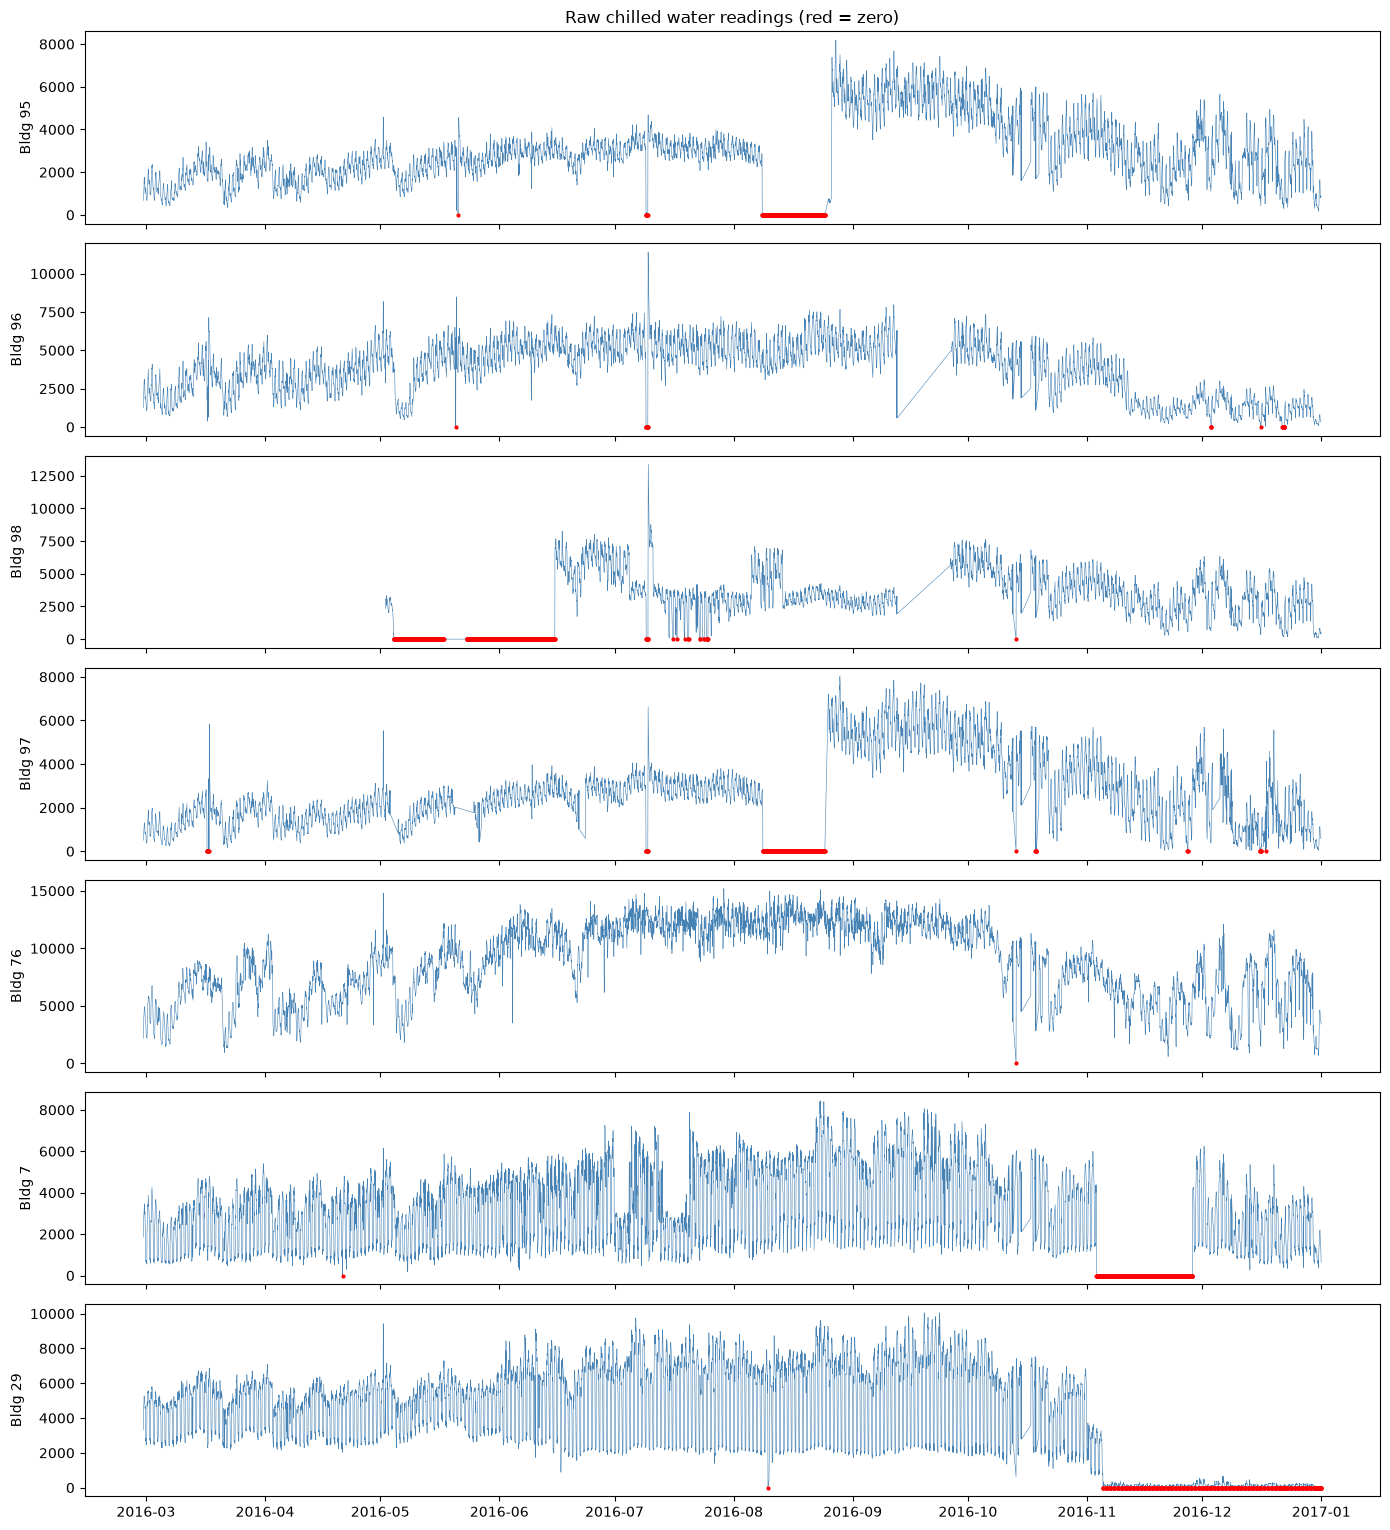

 building_id       first_reading  n_zeros  n_zero_runs  longest_run_hrs          first_zero           last_zero
          95 2016-02-29 09:00:00      402            4              393 2016-05-21 09:00:00 2016-08-24 19:00:00
          96 2016-02-29 09:00:00       30            6               12 2016-05-20 16:00:00 2016-12-22 09:00:00
          98 2016-05-02 10:00:00      892           12              859 2016-05-04 13:00:00 2016-10-13 13:00:00
          97 2016-02-29 09:00:00      426           13              388 2016-03-16 22:00:00 2016-12-17 13:00:00
          76 2016-02-29 09:00:00        1            1                1 2016-10-13 13:00:00 2016-10-13 13:00:00
           7 2016-02-29 09:00:00      602            2              601 2016-04-21 05:00:00 2016-11-28 11:00:00
          29 2016-02-29 09:00:00      469           62               20 2016-08-09 23:00:00 2016-12-31 23:00:00

Hours by number of buildings reading zero at the same time:
0    5069
1    1605
2     581
3       9
4  

In [47]:
raw_sel = meter_1[meter_1['building_id'].isin(SELECTED_BUILDINGS)].copy()
raw_sel['timestamp'] = pd.to_datetime(raw_sel['timestamp'])
raw_sel = raw_sel.sort_values(['building_id', 'timestamp'])

fig, axes = plt.subplots(len(SELECTED_BUILDINGS), 1, figsize=(14, 2.2 * len(SELECTED_BUILDINGS)), sharex=True)
rows = []
for ax, b_id in zip(axes, SELECTED_BUILDINGS):
    b = raw_sel[raw_sel['building_id'] == b_id]
    zero = b['meter_reading'] == 0
    ax.plot(b['timestamp'], b['meter_reading'], lw=0.4, color='steelblue')
    ax.scatter(b.loc[zero, 'timestamp'], b.loc[zero, 'meter_reading'], s=4, color='red', zorder=3)
    ax.set_ylabel(f'Bldg {b_id}')

    run_id = (zero != zero.shift()).cumsum()
    zero_runs = zero.groupby(run_id).agg(['all', 'size'])
    zero_runs = zero_runs[zero_runs['all']]['size']
    rows.append({
        'building_id': b_id,
        'first_reading': b['timestamp'].min(),
        'n_zeros': int(zero.sum()),
        'n_zero_runs': len(zero_runs),
        'longest_run_hrs': int(zero_runs.max()) if len(zero_runs) else 0,
        'first_zero': b.loc[zero, 'timestamp'].min(),
        'last_zero': b.loc[zero, 'timestamp'].max(),
    })

axes[0].set_title('Raw chilled water readings (red = zero)')
plt.tight_layout()
plt.show()

print(pd.DataFrame(rows).to_string(index=False))

# How many of the selected buildings read zero at the same hour?
zero_wide = raw_sel.assign(is_zero=raw_sel['meter_reading'] == 0).pivot_table(
    index='timestamp', columns='building_id', values='is_zero', aggfunc='max')
print("\nHours by number of buildings reading zero at the same time:")
print(zero_wide.sum(axis=1).value_counts().sort_index())

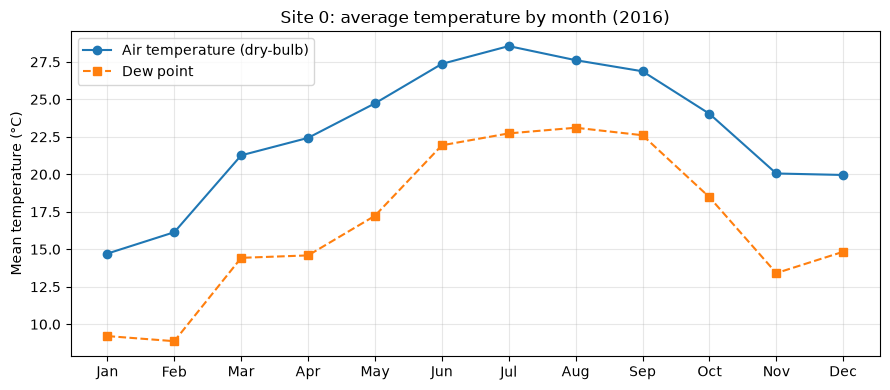

       air_temperature  dew_temperature
month                                  
1                 14.7              9.2
2                 16.1              8.9
3                 21.3             14.4
4                 22.4             14.6
5                 24.7             17.2
6                 27.4             21.9
7                 28.6             22.7
8                 27.6             23.1
9                 26.9             22.6
10                24.0             18.5
11                20.1             13.4
12                20.0             14.8


In [48]:
import os
os.makedirs('figures', exist_ok=True)

w0 = weather_raw[weather_raw['site_id'] == SITE_ID].copy()
w0['month'] = pd.to_datetime(w0['timestamp']).dt.month
monthly = w0.groupby('month')[['air_temperature', 'dew_temperature']].mean()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly.index, monthly['air_temperature'], 'o-', label='Air temperature (dry-bulb)')
ax.plot(monthly.index, monthly['dew_temperature'], 's--', label='Dew point')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax.set_ylabel('Mean temperature (°C)')
ax.set_title(f'Site {SITE_ID}: average temperature by month (2016)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figures/site0_monthly_temperature.png', dpi=120)
plt.show()

print(monthly.round(1))


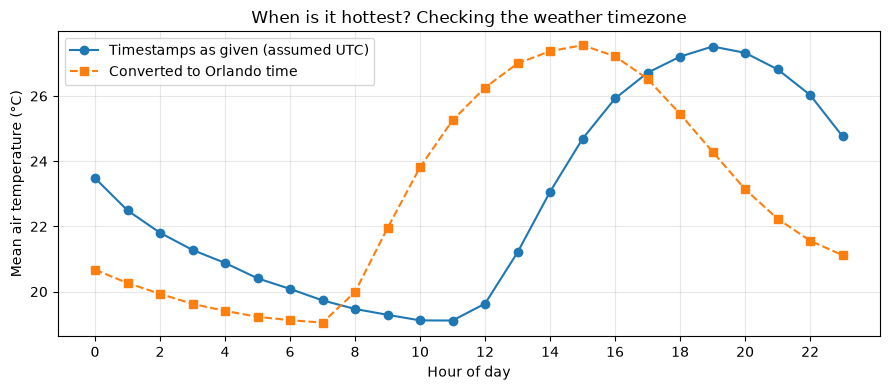

Hottest hour, timestamps as given: 19
Hottest hour, Orlando time:       15


In [49]:
wx = weather_raw[weather_raw['site_id'] == SITE_ID].copy()
wx['ts_utc'] = pd.to_datetime(wx['timestamp']).dt.tz_localize('UTC')
wx['ts_local'] = wx['ts_utc'].dt.tz_convert('America/New_York')

by_hour_utc = wx.groupby(wx['ts_utc'].dt.hour)['air_temperature'].mean()
by_hour_local = wx.groupby(wx['ts_local'].dt.hour)['air_temperature'].mean()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(by_hour_utc.index, by_hour_utc.values, 'o-', label='Timestamps as given (assumed UTC)')
ax.plot(by_hour_local.index, by_hour_local.values, 's--', label='Converted to Orlando time')
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel('Hour of day')
ax.set_ylabel('Mean air temperature (°C)')
ax.set_title('When is it hottest? Checking the weather timezone')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figures/site0_timezone_check.png', dpi=120)
plt.show()

print("Hottest hour, timestamps as given:", by_hour_utc.idxmax())
print("Hottest hour, Orlando time:      ", by_hour_local.idxmax())


In [50]:
ZERO_RUN_LIMIT_HRS = 24   # Miller et al. 2020 (BDG2): zero runs longer than 24 hours are bad data
LOW_FRACTION = 0.10       # "stuck low": daily median below 10% of the building's usual daily median
MIN_STUCK_DAYS = 7        # our choice: only flag low stretches lasting at least a week

def find_stuck_low_start(df):
    daily = df.set_index('timestamp')['meter_reading'].resample('D').median()
    is_low = daily < LOW_FRACTION * daily.median()
    if not is_low.iloc[-1]:
        return None
    start = is_low[~is_low].index.max() + pd.Timedelta(days=1)
    if (daily.index.max() - start).days + 1 < MIN_STUCK_DAYS:
        return None
    return start

def clean_building_data(building_id, meter_1_df):
    df = meter_1_df[meter_1_df['building_id'] == building_id].copy()
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    df = df.sort_values('timestamp').drop_duplicates(subset='timestamp', keep='first').reset_index(drop=True)

    df['flag'] = ''

    is_zero = df['meter_reading'] == 0
    run_id = (is_zero != is_zero.shift()).cumsum()
    run_length = is_zero.groupby(run_id).transform('size')
    df.loc[is_zero & (run_length > ZERO_RUN_LIMIT_HRS), 'flag'] = 'long_zero_run'

    low_start = find_stuck_low_start(df)
    if low_start is not None:
        df.loc[(df['timestamp'] >= low_start) & (df['flag'] == ''), 'flag'] = 'stuck_low'

    return df, low_start

cleaned_data = {}
rows = []
for b_id in SELECTED_BUILDINGS:
    df, low_start = clean_building_data(b_id, meter_1)
    cleaned_data[b_id] = df
    counts = df['flag'].replace('', 'ok').value_counts()
    rows.append({'building_id': b_id,
                 'hours': len(df),
                 'ok': counts.get('ok', 0),
                 'long_zero_run': counts.get('long_zero_run', 0),
                 'stuck_low': counts.get('stuck_low', 0),
                 'stuck_low_starts': low_start.date() if low_start is not None else '-'})

flag_summary = pd.DataFrame(rows).set_index('building_id')
print(flag_summary)


             hours    ok  long_zero_run  stuck_low stuck_low_starts
building_id                                                        
95            7244  6851            393          0                -
96            6933  6933              0          0                -
98            5279  4420            859          0                -
97            6997  6609            388          0                -
76            7269  7269              0          0                -
7             7267  6666            601          0                -
29            7269  5901              0       1368       2016-11-05


In [51]:
# Weather for Site 0
weather = weather_raw[weather_raw['site_id'] == SITE_ID].copy()
# Kaggle weather is UTC; meters are fixed UTC-5 (EST, no daylight saving). Verified against BDG2.
weather['timestamp'] = pd.to_datetime(weather['timestamp']) - pd.Timedelta(hours=5)
weather_use = weather[['timestamp', 'air_temperature', 'dew_temperature']].copy()
weather_use = weather_use.dropna(subset=['air_temperature', 'dew_temperature'])

print(f"Weather: {len(weather_use)} hours")
print(f"Temperature range: {weather_use['air_temperature'].min():.1f}°C to {weather_use['air_temperature'].max():.1f}°C")

# Merge data
all_data = []
for b_id in SELECTED_BUILDINGS:
    df = cleaned_data[b_id][['timestamp', 'meter_reading', 'flag']].copy()
    df['building_id'] = b_id
    all_data.append(df)

energy_df = pd.concat(all_data, ignore_index=True).sort_values(['building_id', 'timestamp'])
data = energy_df.merge(weather_use, on='timestamp', how='inner')

# Add time features
data['hour'] = data['timestamp'].dt.hour
data['day_of_week'] = data['timestamp'].dt.dayofweek
data['month'] = data['timestamp'].dt.month
data['is_weekend'] = data['day_of_week'] >= 5

data = data.merge(metadata[['building_id', 'primary_use', 'square_feet']], on='building_id', how='left')

print(f"\nFinal dataset: {data.shape}")
print(f"Date range: {data['timestamp'].min()} to {data['timestamp'].max()}")
print(f"Buildings: {data['building_id'].nunique()}")

Weather: 8781 hours
Temperature range: 1.7°C to 36.1°C

Final dataset: (48223, 12)
Date range: 2016-02-29 09:00:00 to 2016-12-31 18:00:00
Buildings: 7


---

## Section 3: Physics Features

In [52]:
def wet_bulb_temperature(dry_bulb, dew_point):
    a = 17.27
    b = 237.7
    alpha_dp = (a * dew_point) / (b + dew_point)
    alpha_db = (a * dry_bulb) / (b + dry_bulb)
    rh = 100 * np.exp(alpha_dp - alpha_db)
    rh = np.clip(rh, 0, 100)
    wb = dry_bulb * np.arctan(0.151977 * (rh + 8.313659) ** 0.5) + np.arctan(dry_bulb + rh) - np.arctan(rh - 1.676331) + 0.00391838 * rh ** 1.5 * np.arctan(0.023101 * rh) - 4.686035
    return wb

def enthalpy(dry_bulb, dew_point):
    def vapor_pressure(T):
        return 610.5 * np.exp((17.27 * T) / (237.7 + T))
    P_w_sat = vapor_pressure(dew_point)
    P_atm = 101325
    W = 0.622 * P_w_sat / (P_atm - P_w_sat)
    h = 1.006 * dry_bulb + W * (2501 + 1.86 * dry_bulb)
    return h

data['wet_bulb'] = wet_bulb_temperature(data['air_temperature'], data['dew_temperature'])
data['enthalpy'] = enthalpy(data['air_temperature'], data['dew_temperature'])

print("Psychrometric features calculated:")
print(f"Wet-bulb range: {data['wet_bulb'].min():.1f}°C to {data['wet_bulb'].max():.1f}°C")
print(f"Enthalpy range: {data['enthalpy'].min():.1f} to {data['enthalpy'].max():.1f} kJ/kg")

Psychrometric features calculated:
Wet-bulb range: 2.4°C to 26.9°C
Enthalpy range: 14.7 to 82.9 kJ/kg


Correlation (r) of cooling load with each weather measure, flagged hours excluded:

                         Dry-bulb (°C)  Wet-bulb (°C)  Enthalpy (kJ/kg)
building_id                                                            
7                                0.683          0.550             0.546
29                               0.638          0.432             0.426
76                               0.781          0.944             0.960
95                               0.586          0.656             0.659
96                               0.819          0.827             0.831
97                               0.599          0.663             0.671
98                               0.527          0.482             0.456
median across buildings          0.638          0.656             0.659


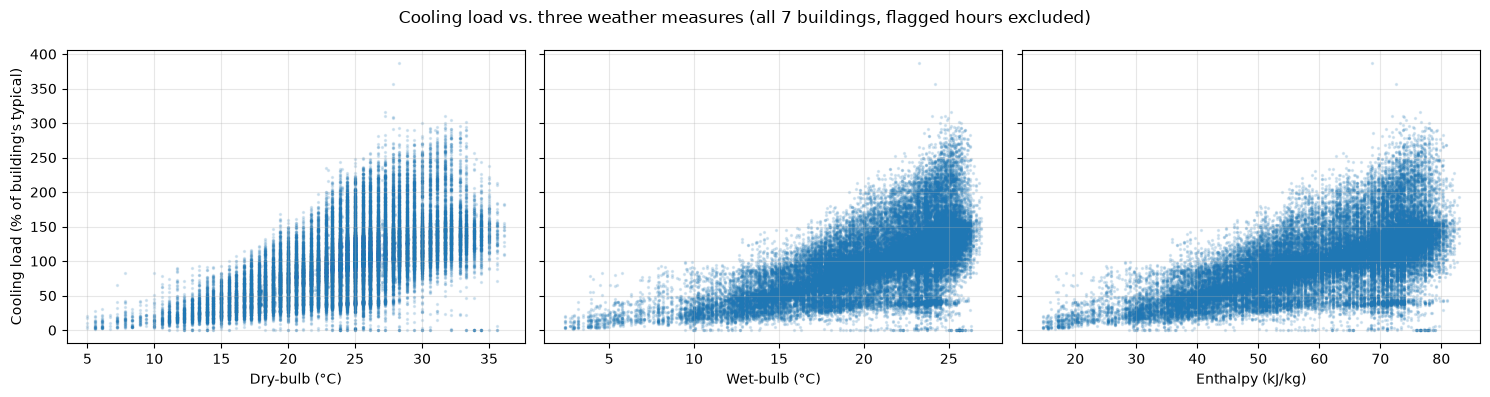

In [53]:
ok = data[data['flag'] == ''].copy()
ok['load_pct_of_typical'] = 100 * ok['meter_reading'] / ok.groupby('building_id')['meter_reading'].transform('median')

features = {'air_temperature': 'Dry-bulb (°C)', 'wet_bulb': 'Wet-bulb (°C)', 'enthalpy': 'Enthalpy (kJ/kg)'}

corr_table = ok.groupby('building_id').apply(
    lambda b: pd.Series({label: b['meter_reading'].corr(b[col]) for col, label in features.items()}),
    include_groups=False
).round(3)
corr_table.loc['median across buildings'] = corr_table.median().round(3)
print("Correlation (r) of cooling load with each weather measure, flagged hours excluded:\n")
print(corr_table)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (col, label) in zip(axes, features.items()):
    ax.scatter(ok[col], ok['load_pct_of_typical'], s=2, alpha=0.15)
    ax.set_xlabel(label)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Cooling load (% of building's typical)")
fig.suptitle('Cooling load vs. three weather measures (all 7 buildings, flagged hours excluded)')
plt.tight_layout()
plt.savefig('figures/load_vs_weather_measures.png', dpi=120)
plt.show()


---

## Section 4: Physics Baseline

In [54]:
def fit_changepoint_model(x, y, n_candidates=50):
    candidates = np.percentile(x, np.linspace(5, 95, n_candidates))
    best = None
    for cp in candidates:
        X = np.column_stack([np.ones_like(x), np.maximum(0, x - cp)])
        coef, *_ = np.linalg.lstsq(X, y, rcond=None)
        sse = np.sum((y - X @ coef) ** 2)
        if best is None or sse < best['sse']:
            best = {'balance_point_c': cp, 'base_load': coef[0], 'slope': coef[1], 'sse': sse}
    rmse = np.sqrt(best['sse'] / len(y))
    best['r2'] = 1 - best['sse'] / np.sum((y - y.mean()) ** 2)
    best['cv_rmse_pct'] = 100 * rmse / y.mean()
    return best

def predict_changepoint(params, x):
    return params['base_load'] + params['slope'] * np.maximum(0, x - params['balance_point_c'])

models = {}
rows = []
for b_id in SELECTED_BUILDINGS:
    b = data[(data['building_id'] == b_id) & (data['flag'] == '')]
    p = fit_changepoint_model(b['wet_bulb'].values, b['meter_reading'].values)
    models[b_id] = p
    rows.append({'building_id': b_id,
                 'hours_used': len(b),
                 'balance_point_C': round(p['balance_point_c'], 1),
                 'balance_point_F': round(p['balance_point_c'] * 9 / 5 + 32, 1),
                 'base_load': round(p['base_load']),
                 'slope_per_C': round(p['slope'], 1),
                 'R2': round(p['r2'], 3),
                 'CV_RMSE_%': round(p['cv_rmse_pct'], 1)})

baseline_table = pd.DataFrame(rows).set_index('building_id')
print("3-parameter cooling change-point model, wet-bulb, unflagged hours only:\n")
print(baseline_table)


3-parameter cooling change-point model, wet-bulb, unflagged hours only:

             hours_used  balance_point_C  balance_point_F  base_load  \
building_id                                                            
95                 6846             11.9             53.5       1077   
96                 6928             13.6             56.5       1122   
98                 4415             12.2             53.9       1961   
97                 6604             12.8             55.0        722   
76                 7264             13.0             55.5       2724   
7                  6661             14.3             57.8       1483   
29                 5901             23.1             73.6       4509   

             slope_per_C     R2  CV_RMSE_%  
building_id                                 
95                 236.8  0.437       35.1  
96                 393.0  0.711       25.0  
98                 193.2  0.215       40.2  
97                 273.9  0.453       42.4  
76      

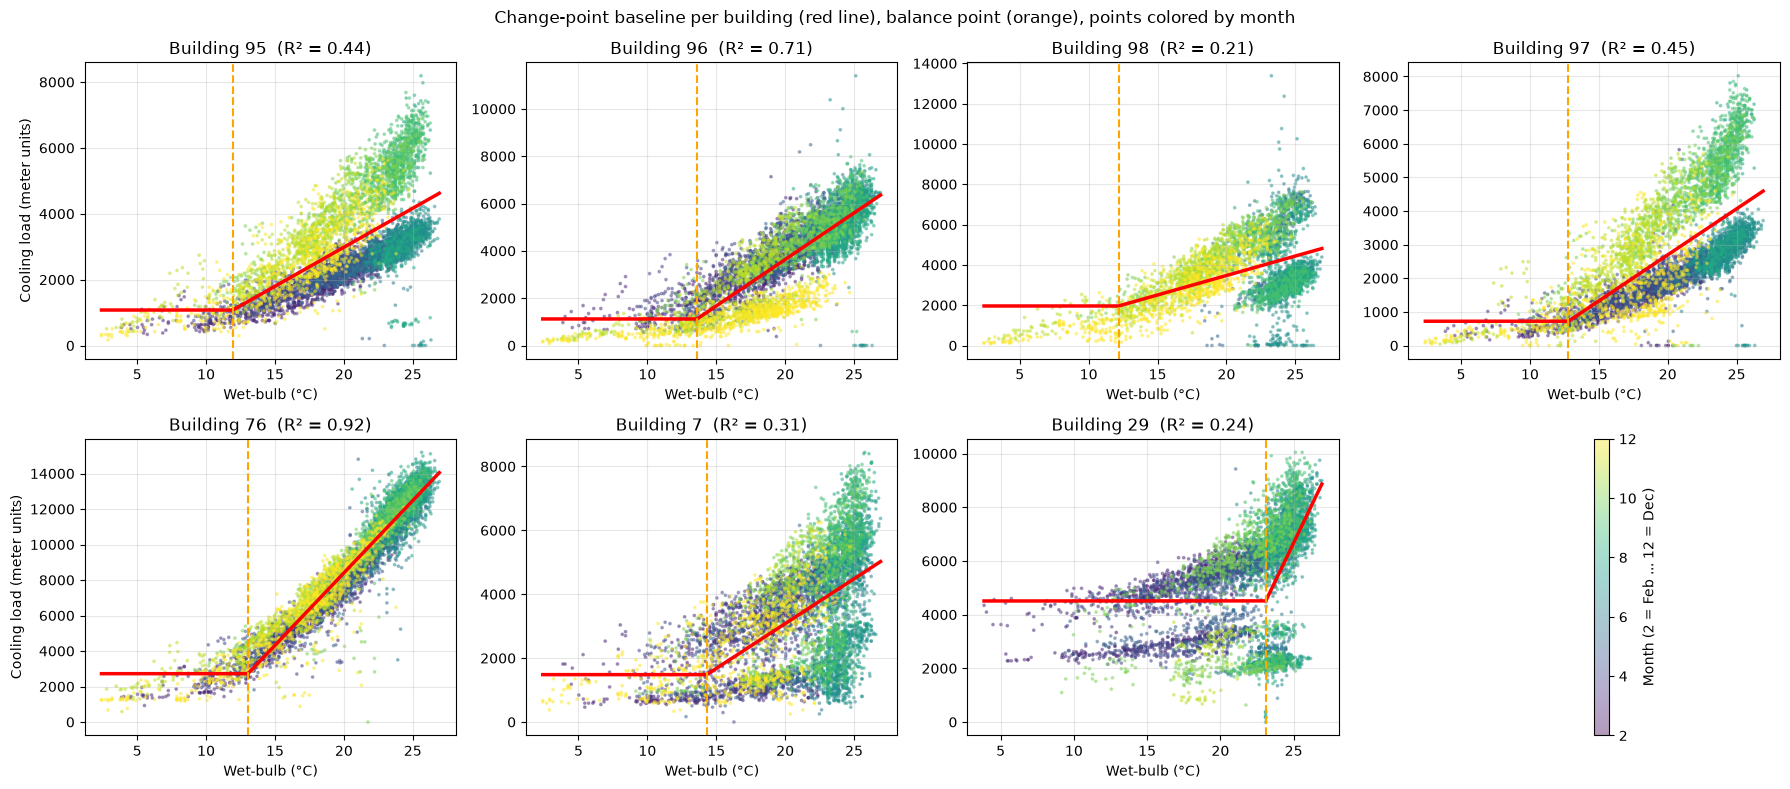

In [55]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()
for ax, b_id in zip(axes, SELECTED_BUILDINGS):
    b = data[(data['building_id'] == b_id) & (data['flag'] == '')]
    p = models[b_id]
    pts = ax.scatter(b['wet_bulb'], b['meter_reading'], c=b['month'], cmap='viridis', s=3, alpha=0.4, vmin=2, vmax=12)
    x_line = np.linspace(b['wet_bulb'].min(), b['wet_bulb'].max(), 200)
    ax.plot(x_line, predict_changepoint(p, x_line), color='red', lw=2.5)
    ax.axvline(p['balance_point_c'], color='orange', ls='--', lw=1.5)
    ax.set_title(f"Building {b_id}  (R² = {p['r2']:.2f})")
    ax.set_xlabel('Wet-bulb (°C)')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Cooling load (meter units)')
axes[4].set_ylabel('Cooling load (meter units)')
axes[-1].axis('off')
fig.colorbar(pts, ax=axes[-1], label='Month (2 = Feb ... 12 = Dec)', fraction=0.5)
fig.suptitle('Change-point baseline per building (red line), balance point (orange), points colored by month')
plt.tight_layout()
plt.savefig('figures/changepoint_baselines.png', dpi=120)
plt.show()


Hours per building (unflagged):
             train (Mar-Jul)  test (Aug-Dec)
building_id                                 
7                       3687            2974
29                      3687            2214
76                      3687            3577
95                      3680            3166
96                      3687            3241
97                      3477            3127
98                      1171            3244


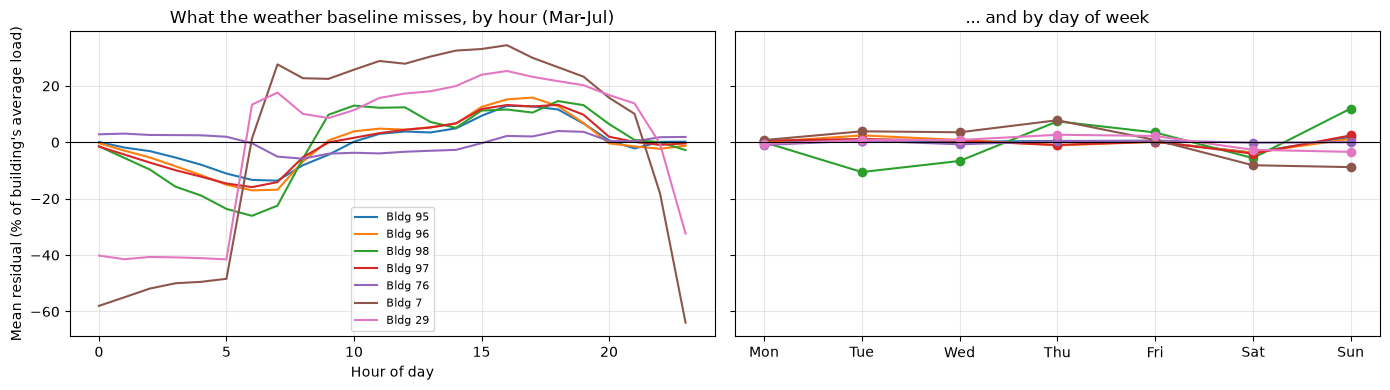

In [56]:
SPLIT_DATE = pd.Timestamp('2016-08-01')

ok = data[data['flag'] == ''].copy()
train = ok[ok['timestamp'] < SPLIT_DATE].copy()
test = ok[ok['timestamp'] >= SPLIT_DATE].copy()

train_models = {}
for b_id in SELECTED_BUILDINGS:
    b = train[train['building_id'] == b_id]
    train_models[b_id] = fit_changepoint_model(b['wet_bulb'].values, b['meter_reading'].values)

for df in (train, test):
    df['baseline_pred'] = np.nan
    for b_id, p in train_models.items():
        m = df['building_id'] == b_id
        df.loc[m, 'baseline_pred'] = predict_changepoint(p, df.loc[m, 'wet_bulb'].values)
    df['residual'] = df['meter_reading'] - df['baseline_pred']

print("Hours per building (unflagged):")
print(pd.DataFrame({'train (Mar-Jul)': train.groupby('building_id').size(),
                    'test (Aug-Dec)': test.groupby('building_id').size()}))

train['residual_pct'] = 100 * train['residual'] / train.groupby('building_id')['meter_reading'].transform('mean')
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for b_id in SELECTED_BUILDINGS:
    b = train[train['building_id'] == b_id]
    axes[0].plot(b.groupby('hour')['residual_pct'].mean(), label=f'Bldg {b_id}')
    axes[1].plot(b.groupby('day_of_week')['residual_pct'].mean(), marker='o')
axes[0].set_xlabel('Hour of day')
axes[0].set_ylabel("Mean residual (% of building's average load)")
axes[0].set_title('What the weather baseline misses, by hour (Mar-Jul)')
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
axes[1].set_title('... and by day of week')
for ax in axes:
    ax.axhline(0, color='black', lw=0.8)
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig('figures/residual_by_hour_and_day.png', dpi=120)
plt.show()


In [57]:
from sklearn.ensemble import HistGradientBoostingRegressor

ML_FEATURES = ['wet_bulb', 'air_temperature', 'dew_temperature', 'hour', 'day_of_week']
RESIDUAL_FEATURES = ['hour', 'day_of_week', 'dew_temperature']

def cv_rmse(actual, pred):
    return 100 * np.sqrt(np.mean((actual - pred) ** 2)) / np.mean(actual)

def nmbe(actual, pred):
    return 100 * np.mean(actual - pred) / np.mean(actual)

test['ml_pred'] = np.nan
test['hybrid_pred'] = np.nan
rows = []
for b_id in SELECTED_BUILDINGS:
    tr = train[train['building_id'] == b_id]
    m = test['building_id'] == b_id
    te = test[m]

    ml = HistGradientBoostingRegressor(random_state=0).fit(tr[ML_FEATURES], tr['meter_reading'])
    resid_model = HistGradientBoostingRegressor(random_state=0).fit(tr[RESIDUAL_FEATURES], tr['residual'])
    test.loc[m, 'ml_pred'] = ml.predict(te[ML_FEATURES])
    test.loc[m, 'hybrid_pred'] = te['baseline_pred'] + resid_model.predict(te[RESIDUAL_FEATURES])

    for name, col in [('baseline', 'baseline_pred'), ('ml_only', 'ml_pred'), ('hybrid', 'hybrid_pred')]:
        rows.append({'building_id': b_id, 'model': name,
                     'CV_RMSE_%': cv_rmse(te['meter_reading'], test.loc[m, col]),
                     'NMBE_%': nmbe(te['meter_reading'], test.loc[m, col])})

results = pd.DataFrame(rows)
cv_table = results.pivot(index='building_id', columns='model', values='CV_RMSE_%')[['baseline', 'ml_only', 'hybrid']]
bias_table = results.pivot(index='building_id', columns='model', values='NMBE_%')[['baseline', 'ml_only', 'hybrid']]
cv_table.loc['median'] = cv_table.median()
bias_table.loc['median'] = bias_table.median()

print("Test period (Aug-Dec). CV(RMSE) %, lower is better:\n")
print(cv_table.round(1))
print("\nNMBE % (positive = building used MORE than predicted):\n")
print(bias_table.round(1))


Test period (Aug-Dec). CV(RMSE) %, lower is better:

model        baseline  ml_only  hybrid
building_id                           
7                44.3     29.1    29.9
29               39.3     17.0    18.9
76               12.0     11.4    11.8
95               49.0     49.6    48.9
96               34.8     32.4    35.5
97               57.3     57.8    57.0
98               42.5     42.6    58.6
median           42.5     32.4    35.5

NMBE % (positive = building used MORE than predicted):

model        baseline  ml_only  hybrid
building_id                           
7                16.5     18.6    18.1
29                0.0     -0.1     1.3
76                6.3      6.5     6.1
95               38.6     40.2    38.6
96              -15.2    -11.8   -14.6
97               42.8     44.4    42.9
98               -8.7      1.8   -23.8
median            6.3      6.5     6.1


---

## Section 6: Uncertainty


In [58]:
def fit_hybrid(train_df):
    fitted = {}
    for b_id, b in train_df.groupby('building_id'):
        cp = fit_changepoint_model(b['wet_bulb'].values, b['meter_reading'].values)
        resid = b['meter_reading'].values - predict_changepoint(cp, b['wet_bulb'].values)
        rm = HistGradientBoostingRegressor(random_state=0).fit(b[RESIDUAL_FEATURES], resid)
        fitted[b_id] = (cp, rm)
    return fitted

def predict_hybrid(fitted, df):
    pred = pd.Series(np.nan, index=df.index)
    for b_id, (cp, rm) in fitted.items():
        m = df['building_id'] == b_id
        if m.any():
            pred[m] = predict_changepoint(cp, df.loc[m, 'wet_bulb'].values) + rm.predict(df.loc[m, RESIDUAL_FEATURES])
    return pred

def conformal_halfwidths(fitted, cal_df, coverage=0.90):
    abs_err = (cal_df['meter_reading'] - predict_hybrid(fitted, cal_df)).abs()
    halfwidths = {}
    for b_id, e in abs_err.groupby(cal_df['building_id']):
        n = len(e)
        level = min(1.0, np.ceil((n + 1) * coverage) / n)
        halfwidths[b_id] = e.quantile(level)
    return pd.Series(halfwidths)


Target coverage: 90%. Fit on Mar-Jun, calibrated on Jul, tested on Aug-Dec.

               band ± (meter units)  inside band %  above band %  below band %
building_id                                                                   
7                            2197.0           97.0           2.7           0.2
29                           1100.0           81.2           9.5           9.3
76                           1768.0           91.9           6.0           2.1
95                            530.0           20.8          76.9           2.4
96                            915.0           63.4           4.6          31.9
97                            601.0           25.9          69.9           4.1
98                           4931.0           99.8           0.0           0.2
all buildings                   NaN           68.4          24.5           7.1


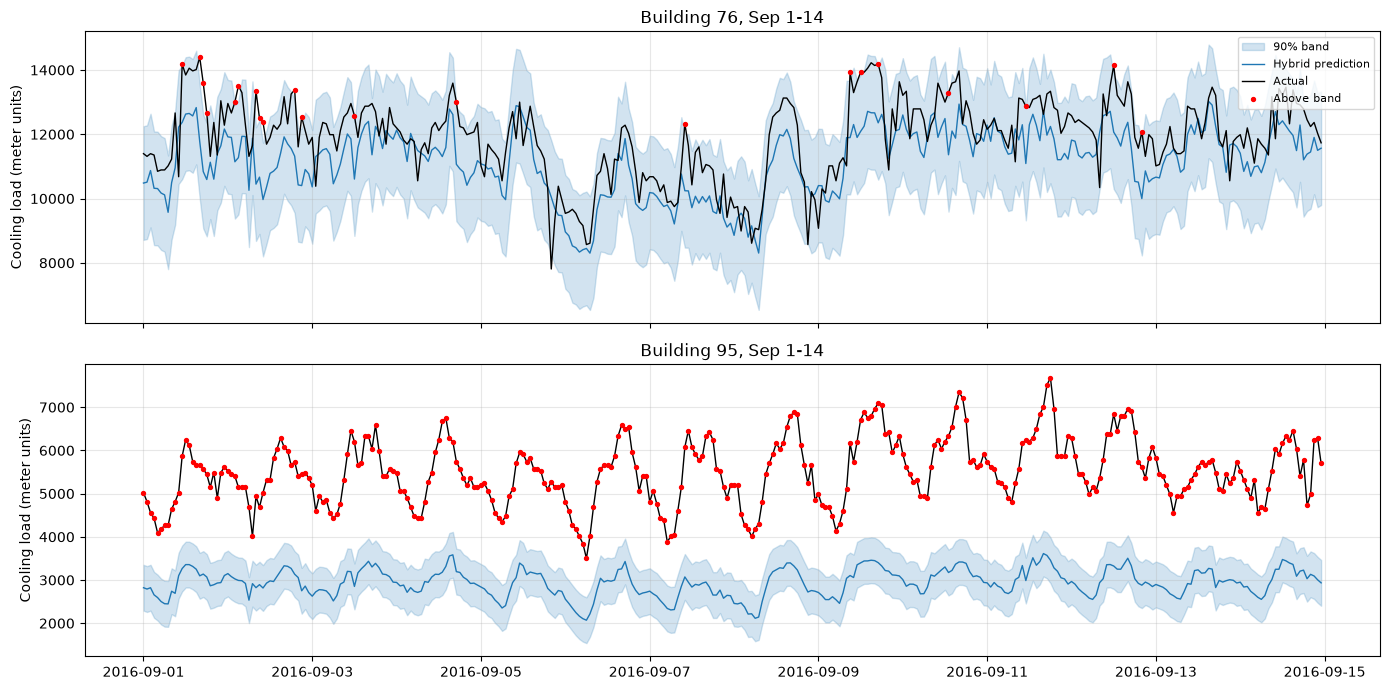

In [59]:
CAL_START = pd.Timestamp('2016-07-01')

fit_part = ok[ok['timestamp'] < CAL_START]
cal_part = ok[(ok['timestamp'] >= CAL_START) & (ok['timestamp'] < SPLIT_DATE)]
test_part = ok[ok['timestamp'] >= SPLIT_DATE].copy()

hybrid_fit = fit_hybrid(fit_part)
halfwidth = conformal_halfwidths(hybrid_fit, cal_part, coverage=0.90)

test_part['pred'] = predict_hybrid(hybrid_fit, test_part)
test_part['lower'] = test_part['pred'] - test_part['building_id'].map(halfwidth)
test_part['upper'] = test_part['pred'] + test_part['building_id'].map(halfwidth)
test_part['inside'] = test_part['meter_reading'].between(test_part['lower'], test_part['upper'])
test_part['above'] = test_part['meter_reading'] > test_part['upper']
test_part['below'] = test_part['meter_reading'] < test_part['lower']

coverage_table = test_part.groupby('building_id')[['inside', 'above', 'below']].mean().mul(100).round(1)
coverage_table.columns = ['inside band %', 'above band %', 'below band %']
coverage_table.insert(0, 'band ± (meter units)', halfwidth.round(0))
coverage_table.loc['all buildings'] = [np.nan] + list(test_part[['inside', 'above', 'below']].mean().mul(100).round(1))
print("Target coverage: 90%. Fit on Mar-Jun, calibrated on Jul, tested on Aug-Dec.\n")
print(coverage_table)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
window = (test_part['timestamp'] >= '2016-09-01') & (test_part['timestamp'] < '2016-09-15')
for ax, b_id in zip(axes, [76, 95]):
    w = test_part[window & (test_part['building_id'] == b_id)]
    ax.fill_between(w['timestamp'], w['lower'], w['upper'], color='tab:blue', alpha=0.2, label='90% band')
    ax.plot(w['timestamp'], w['pred'], color='tab:blue', lw=1, label='Hybrid prediction')
    ax.plot(w['timestamp'], w['meter_reading'], color='black', lw=1, label='Actual')
    ax.scatter(w.loc[w['above'], 'timestamp'], w.loc[w['above'], 'meter_reading'], color='red', s=8, zorder=3, label='Above band')
    ax.set_title(f'Building {b_id}, Sep 1-14')
    ax.set_ylabel('Cooling load (meter units)')
    ax.grid(alpha=0.3)
axes[0].legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.savefig('figures/prediction_bands_example.png', dpi=120)
plt.show()


---

## Section 7: Backtest


Rolling-origin backtest: each month, fit on all earlier months except the last,
calibrate the 90% band on the month just before, test on the month itself.

           trained through  buildings judged  median CV_RMSE_%  coverage_%  \
test month                                                                   
Jun                    Apr                 6              15.8        74.1   
Jul                    May                 6              20.7        73.8   
Aug                    Jun                 7              24.3        85.5   
Sep                    Jul                 7              31.2        86.3   
Oct                    Aug                 7              21.9        92.9   
Nov                    Sep                 7              56.9        80.1   
Dec                    Oct                 5              52.4        80.2   

            above_%  
test month           
Jun            18.6  
Jul            16.4  
Aug            11.3  
Sep            12.1  
Oct      

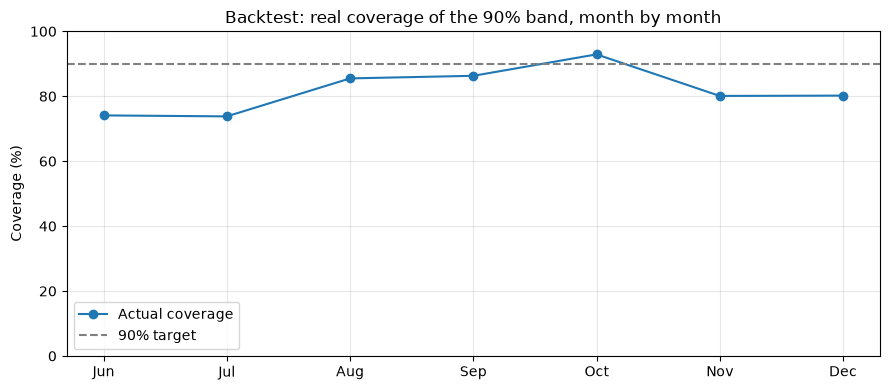

In [60]:
MIN_HOURS = 168  # need at least one week of fit and calibration data to judge a building

monthly_rows, building_rows = [], []
for test_start in pd.date_range('2016-06-01', '2016-12-01', freq='MS'):
    cal_start = test_start - pd.DateOffset(months=1)
    test_end = test_start + pd.DateOffset(months=1)
    fit_df = ok[ok['timestamp'] < cal_start]
    cal_df = ok[(ok['timestamp'] >= cal_start) & (ok['timestamp'] < test_start)]
    test_df = ok[(ok['timestamp'] >= test_start) & (ok['timestamp'] < test_end)]

    judged = [b for b in SELECTED_BUILDINGS
              if (fit_df['building_id'] == b).sum() >= MIN_HOURS
              and (cal_df['building_id'] == b).sum() >= MIN_HOURS
              and (test_df['building_id'] == b).any()]

    fitted = fit_hybrid(fit_df[fit_df['building_id'].isin(judged)])
    hw = conformal_halfwidths(fitted, cal_df[cal_df['building_id'].isin(judged)])
    t = test_df[test_df['building_id'].isin(judged)].copy()
    t['pred'] = predict_hybrid(fitted, t)
    t['inside'] = (t['meter_reading'] - t['pred']).abs() <= t['building_id'].map(hw)
    t['above'] = t['meter_reading'] > t['pred'] + t['building_id'].map(hw)

    month = test_start.strftime('%b')
    per_b = []
    for b_id, b in t.groupby('building_id'):
        row = {'month': month, 'building_id': b_id,
               'CV_RMSE_%': cv_rmse(b['meter_reading'], b['pred']),
               'coverage_%': 100 * b['inside'].mean(),
               'above_%': 100 * b['above'].mean()}
        building_rows.append(row)
        per_b.append(row)
    per_b = pd.DataFrame(per_b)
    monthly_rows.append({'test month': month,
                         'trained through': (cal_start - pd.Timedelta(days=1)).strftime('%b'),
                         'buildings judged': len(judged),
                         'median CV_RMSE_%': per_b['CV_RMSE_%'].median(),
                         'coverage_%': 100 * t['inside'].mean(),
                         'above_%': 100 * t['above'].mean()})

backtest = pd.DataFrame(monthly_rows).set_index('test month').round(1)
by_building = pd.DataFrame(building_rows)
coverage_grid = by_building.pivot(index='building_id', columns='month', values='coverage_%')
coverage_grid = coverage_grid[[m for m in backtest.index if m in coverage_grid.columns]].round(0)

print("Rolling-origin backtest: each month, fit on all earlier months except the last,")
print("calibrate the 90% band on the month just before, test on the month itself.\n")
print(backtest)
print("\nCoverage % by building and test month (blank = not enough data to judge):\n")
print(coverage_grid.to_string(na_rep=''))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(backtest.index, backtest['coverage_%'], 'o-', label='Actual coverage')
ax.axhline(90, color='gray', ls='--', label='90% target')
ax.set_ylabel('Coverage (%)')
ax.set_ylim(0, 100)
ax.set_title('Backtest: real coverage of the 90% band, month by month')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figures/backtest_coverage_by_month.png', dpi=120)
plt.show()


---

## Section 8: New-Building Onboarding (Cold Start)


In [61]:
ONBOARD_START = pd.Timestamp('2016-09-01')
ADAPT_END = pd.Timestamp('2016-09-15')   # weeks 1-2: fit Model A / adapt Model B
CAL_END = pd.Timestamp('2016-09-22')     # week 3: calibrate the 90% band
TEST_END = pd.Timestamp('2016-11-01')    # test: Sep 22 - Oct 31

def fit_pooled(df):
    d = df.copy()
    d['load_norm'] = d['meter_reading'] / d.groupby('building_id')['meter_reading'].transform('mean')
    cp = fit_changepoint_model(d['wet_bulb'].values, d['load_norm'].values)
    resid = d['load_norm'].values - predict_changepoint(cp, d['wet_bulb'].values)
    rm = HistGradientBoostingRegressor(random_state=0).fit(d[RESIDUAL_FEATURES], resid)
    return cp, rm

def predict_pooled_shape(pooled, df):
    cp, rm = pooled
    return predict_changepoint(cp, df['wet_bulb'].values) + rm.predict(df[RESIDUAL_FEATURES])

def band_halfwidth(actual, pred, coverage=0.90):
    err = np.abs(np.asarray(actual) - np.asarray(pred))
    n = len(err)
    return np.quantile(err, min(1.0, np.ceil((n + 1) * coverage) / n))

rows = []
for b_id in SELECTED_BUILDINGS:
    new = ok[ok['building_id'] == b_id]
    adapt = new[(new['timestamp'] >= ONBOARD_START) & (new['timestamp'] < ADAPT_END)]
    cal = new[(new['timestamp'] >= ADAPT_END) & (new['timestamp'] < CAL_END)]
    tst = new[(new['timestamp'] >= CAL_END) & (new['timestamp'] < TEST_END)]
    if len(adapt) < 168 or len(cal) < 72 or len(tst) < 168:
        continue

    model_a = fit_hybrid(adapt)
    pred_a_cal, pred_a_test = predict_hybrid(model_a, cal), predict_hybrid(model_a, tst)

    others = ok[(ok['building_id'] != b_id) & (ok['timestamp'] < ONBOARD_START)]
    pooled = fit_pooled(others)
    shape_adapt = predict_pooled_shape(pooled, adapt)
    scale = np.sum(adapt['meter_reading'].values * shape_adapt) / np.sum(shape_adapt ** 2)
    pred_b_cal = scale * predict_pooled_shape(pooled, cal)
    pred_b_test = scale * predict_pooled_shape(pooled, tst)

    for name, p_cal, p_test in [('A: alone', pred_a_cal, pred_a_test), ('B: pooled + adapt', pred_b_cal, pred_b_test)]:
        hw = band_halfwidth(cal['meter_reading'], p_cal)
        rows.append({'building_id': b_id, 'model': name,
                     'CV_RMSE_%': cv_rmse(tst['meter_reading'].values, np.asarray(p_test)),
                     'coverage_%': 100 * np.mean(np.abs(tst['meter_reading'].values - np.asarray(p_test)) <= hw)})

cold = pd.DataFrame(rows)
cold_cv = cold.pivot(index='building_id', columns='model', values='CV_RMSE_%')
cold_cov = cold.pivot(index='building_id', columns='model', values='coverage_%')
cold_cv.loc['median'] = cold_cv.median()
cold_cov.loc['median'] = cold_cov.median()

print("Cold start: each building in turn treated as 'new' with only Sep 1-21 data.")
print("Tested Sep 22 - Oct 31.\n")
print("CV(RMSE) %, lower is better:")
print(cold_cv.round(1))
print("\nCoverage of the 90% band %:")
print(cold_cov.round(1))


Cold start: each building in turn treated as 'new' with only Sep 1-21 data.
Tested Sep 22 - Oct 31.

CV(RMSE) %, lower is better:
model        A: alone  B: pooled + adapt
building_id                             
7                20.7               30.3
29               17.4               31.4
76               21.8               19.8
95               24.7               17.0
97               25.8               19.4
median           21.8               19.8

Coverage of the 90% band %:
model        A: alone  B: pooled + adapt
building_id                             
7                89.9               96.0
29               88.4               95.9
76               61.5               97.2
95               50.5               94.5
97               61.6               94.7
median           61.6               95.9


---

## Section 9: Drift


In [62]:
MONITOR_START = pd.Timestamp('2016-07-01')
ROLL_DAYS = 7               # smooth over a week so one odd day can't trigger an alert
ALERT_THRESHOLD_PCT = 15    # our choice: running 15% of typical load above expected
ALERT_PERSIST_DAYS = 3      # our choice: must stay above threshold 3 days in a row

monitor = ok[ok['timestamp'] >= MONITOR_START].copy()

# Policy 1, "frozen": the Mar-Jun model from Section 6, never retrained
monitor['pred_frozen'] = predict_hybrid(hybrid_fit, monitor)

# Policy 2, "auto-retrain": refit every month on all earlier data (like Section 7)
monitor['pred_retrained'] = np.nan
for month_start in pd.date_range(MONITOR_START, '2016-12-01', freq='MS'):
    in_month = (monitor['timestamp'] >= month_start) & (monitor['timestamp'] < month_start + pd.DateOffset(months=1))
    refit = fit_hybrid(ok[ok['timestamp'] < month_start])
    monitor.loc[in_month, 'pred_retrained'] = predict_hybrid(refit, monitor[in_month])

typical_load = fit_part.groupby('building_id')['meter_reading'].mean()
for policy in ['frozen', 'retrained']:
    monitor[f'resid_pct_{policy}'] = (100 * (monitor['meter_reading'] - monitor[f'pred_{policy}'])
                                      / monitor['building_id'].map(typical_load))

def rolling_daily(b, col):
    daily = b.set_index('timestamp')[col].resample('D').mean()
    return daily.rolling(f'{ROLL_DAYS}D', min_periods=4).mean()

def alert_days(rolled):
    above = rolled > ALERT_THRESHOLD_PCT
    streak = above.groupby((~above).cumsum()).cumsum()
    return streak[streak >= ALERT_PERSIST_DAYS].index

drift = {}
rows = []
for b_id in SELECTED_BUILDINGS:
    b = monitor[monitor['building_id'] == b_id]
    drift[b_id] = {p: rolling_daily(b, f'resid_pct_{p}') for p in ['frozen', 'retrained']}
    row = {'building_id': b_id}
    for p in ['frozen', 'retrained']:
        days = alert_days(drift[b_id][p])
        row[f'{p}: first alert'] = days[0].date() if len(days) else '-'
        row[f'{p}: days in alert'] = len(days)
    rows.append(row)

alert_table = pd.DataFrame(rows).set_index('building_id')
print(f"Alert rule: 7-day average residual above +{ALERT_THRESHOLD_PCT}% of typical load "
      f"for {ALERT_PERSIST_DAYS}+ days in a row. Monitoring Jul 1 - Dec 31.\n")
print(alert_table)


Alert rule: 7-day average residual above +15% of typical load for 3+ days in a row. Monitoring Jul 1 - Dec 31.

            frozen: first alert  frozen: days in alert retrained: first alert  \
building_id                                                                     
95                   2016-08-30                    116             2016-08-30   
96                            -                      0                      -   
98                   2016-10-01                      2             2016-10-01   
97                   2016-08-30                    105             2016-08-30   
76                   2016-11-04                      3             2016-11-05   
7                    2016-08-05                     82             2016-08-05   
29                   2016-09-25                      3             2016-09-24   

             retrained: days in alert  
building_id                            
95                                101  
96                                  0 

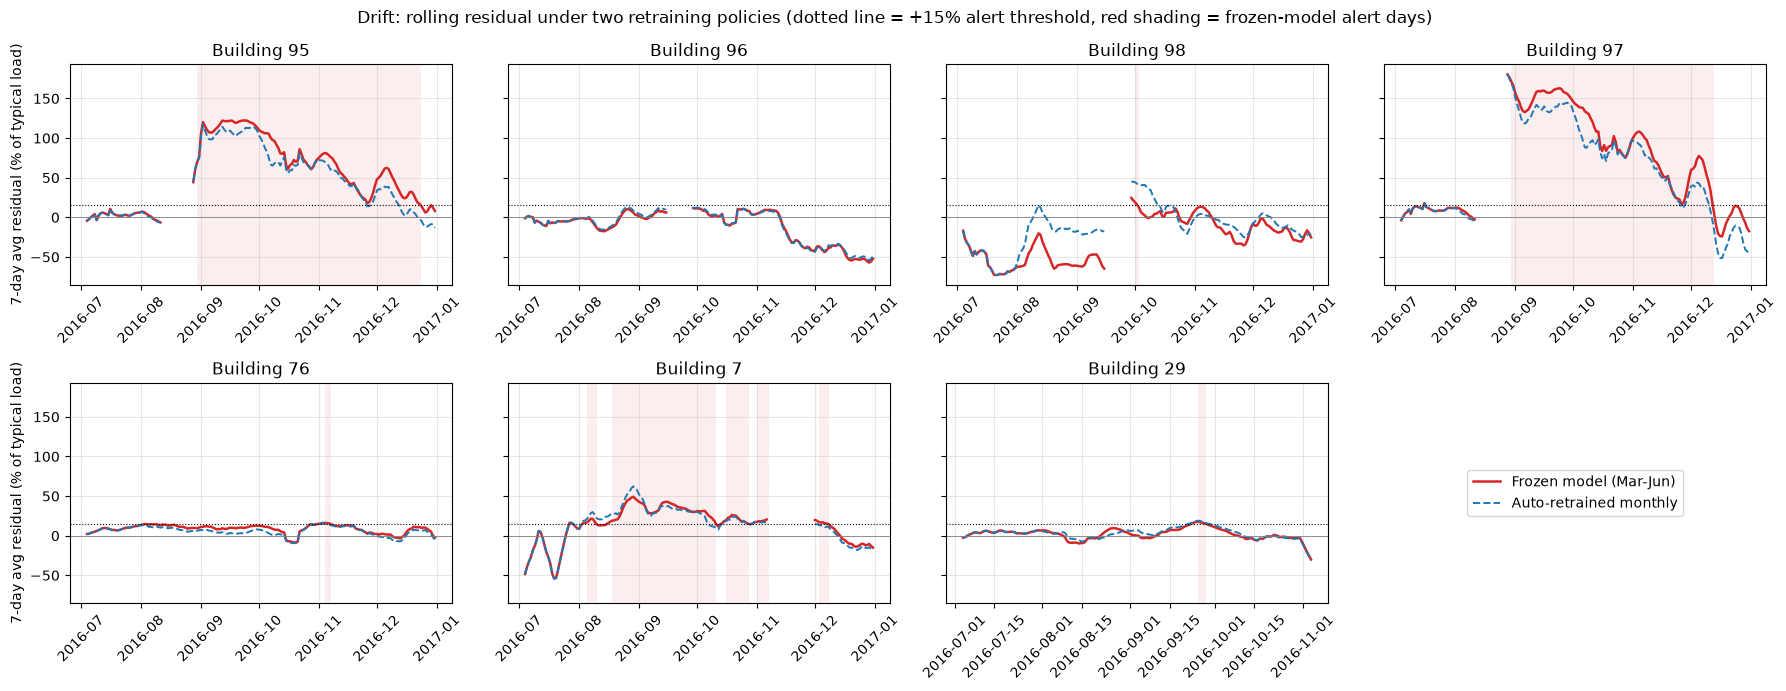

In [63]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharey=True)
axes = axes.ravel()
for ax, b_id in zip(axes, SELECTED_BUILDINGS):
    fr, rt = drift[b_id]['frozen'], drift[b_id]['retrained']
    ax.plot(fr.index, fr.values, color='tab:red', lw=1.8, label='Frozen model (Mar-Jun)')
    ax.plot(rt.index, rt.values, color='tab:blue', lw=1.4, ls='--', label='Auto-retrained monthly')
    ax.axhline(ALERT_THRESHOLD_PCT, color='black', lw=0.8, ls=':')
    ax.axhline(0, color='gray', lw=0.6)
    for d in alert_days(fr):
        ax.axvspan(d, d + pd.Timedelta(days=1), color='tab:red', alpha=0.08, lw=0)
    ax.set_title(f'Building {b_id}')
    ax.tick_params(axis='x', labelrotation=45)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('7-day avg residual (% of typical load)')
axes[4].set_ylabel('7-day avg residual (% of typical load)')
axes[-1].axis('off')
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc='center', fontsize=10)
fig.suptitle(f'Drift: rolling residual under two retraining policies (dotted line = +{ALERT_THRESHOLD_PCT}% alert threshold, red shading = frozen-model alert days)')
plt.tight_layout()
plt.savefig('figures/drift_rolling_residual.png', dpi=120)
plt.show()


---

## Section 10: Flag and Quantify


In [65]:
KBTU_PER_KWH = 3.412        # verified: Kaggle chilled water = BDG2 kWh x 3.412, so readings are kBTU
KBTU_PER_TON_HOUR = 12.0    # 1 ton of cooling = 12,000 BTU per hour
PLANT_COP = 3.5             # assumption: whole chilled-water plant (chillers + pumps + towers)
PRICE_PER_KWH = 0.11        # assumption: Florida commercial ~11-12 cents/kWh (EIA-cited sources)
CO2_KG_PER_KWH = 0.37       # assumption: EPA eGRID2022, Florida (FRCC) ~814 lb CO2/MWh
TRUST_CV_RMSE_MAX = 30.0    # ASHRAE Guideline 14 hourly accuracy bar (same as Heat Check)
FLAG_ABOVE_PCT = 10.0       # our choice: 2x the ~5% of hours expected above a 90% band by chance

cal_pred = predict_hybrid(hybrid_fit, cal_part)
cal_cv = {b_id: cv_rmse(b['meter_reading'], cal_pred[b.index]) for b_id, b in cal_part.groupby('building_id')}

def excess_to_impact(excess_kbtu, cop=PLANT_COP):
    electricity_kwh = excess_kbtu / KBTU_PER_KWH / cop
    return electricity_kwh, electricity_kwh * PRICE_PER_KWH, electricity_kwh * CO2_KG_PER_KWH / 1000

tp = test_part.copy()
tp['excess_kbtu'] = (tp['meter_reading'] - tp['upper']).clip(lower=0)

rows = []
for b_id, b in tp.groupby('building_id'):
    above_pct = 100 * b['above'].mean()
    if cal_cv[b_id] > TRUST_CV_RMSE_MAX:
        verdict = "Can't judge"
    elif above_pct > FLAG_ABOVE_PCT:
        verdict = 'Flagged'
    else:
        verdict = 'Within expected range'
    row = {'building_id': b_id,
           'use': metadata.set_index('building_id').loc[b_id, 'primary_use'],
           'calib CV(RMSE) %': round(cal_cv[b_id], 1),
           'hours above band %': round(above_pct, 1),
           'verdict': verdict}
    if verdict == 'Flagged':
        excess = b['excess_kbtu'].sum()
        kwh, dollars, tonnes = excess_to_impact(excess)
        row.update({'excess ton-hours': round(excess / KBTU_PER_TON_HOUR),
                    'excess % of cooling': round(100 * excess / b['meter_reading'].sum(), 1),
                    'electricity kWh': round(kwh),
                    'cost $': round(dollars),
                    'CO2 tonnes': round(tonnes, 1)})
    rows.append(row)

impact = pd.DataFrame(rows).set_index('building_id')
impact = impact.sort_values('cost $', ascending=False, na_position='last')
print(f"Aug 1 - Dec 31, 2016 (unflagged hours). Excess = cooling above the 90% band's upper edge.\n")
print(impact.to_string(na_rep='-'))

flagged = tp[tp['building_id'].isin(impact.index[impact['verdict'] == 'Flagged'])]
total_excess = flagged['excess_kbtu'].sum()
print(f"\nTotal for flagged buildings: {total_excess / KBTU_PER_TON_HOUR:,.0f} ton-hours of excess cooling")
print("\nSensitivity to the chiller plant COP (the least certain assumption):")
for cop in [2.5, 3.5, 5.0]:
    kwh, dollars, tonnes = excess_to_impact(total_excess, cop)
    print(f"  COP {cop}: {kwh:>9,.0f} kWh   ${dollars:>8,.0f}   {tonnes:>5.1f} tonnes CO2")

excess_vs_pred = (flagged['meter_reading'] - flagged['pred']).clip(lower=0).sum()
_, d_edge, t_edge = excess_to_impact(total_excess)
_, d_pred, t_pred = excess_to_impact(excess_vs_pred)
print(f"\nConservative check: measured above the band edge = ${d_edge:,.0f} ({t_edge:.1f} t CO2); "
      f"measured above the prediction = ${d_pred:,.0f} ({t_pred:.1f} t CO2), {d_pred / d_edge:.2f}x more.")

  


Aug 1 - Dec 31, 2016 (unflagged hours). Excess = cooling above the 90% band's upper edge.

                             use  calib CV(RMSE) %  hours above band %                verdict  excess ton-hours  excess % of cooling  electricity kWh   cost $  CO2 tonnes
building_id                                                                                                                                                               
97           Lodging/residential              19.3                69.9                Flagged          298874.0                 32.7         300325.0  33036.0       111.1
95           Lodging/residential              16.4                76.9                Flagged          280669.0                 28.3         282032.0  31024.0       104.4
7                      Education              38.7                 2.7            Can't judge                 -                    -                -        -           -
29                     Education              11.4    